In [3]:
%pip install scimap

import scimap as sm
download_directory = r'C:\Users\chuab\Desktop\SciMap_project'
sm.hl.downloadDemoData (download_directory)

Note: you may need to restart the kernel to use updated packages.


scimapExampleData.zip: 100%|██████████| 287M/287M [00:43<00:00, 6.84MiB/s] 

Downloaded scimapExampleData.zip to C:\Users\chuab\Desktop\SciMap_project\scimapExampleData.zip


In [5]:
# UPDATE this path to point to your actual file
# The 'r' is important for Windows paths
# The file is inside the "quantification" subfolder
feature_table_path = [r"C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\quantification\exemplar-001--unmicst_cell.csv"]

# Create the annData object
adata = sm.pp.mcmicro_to_scimap(feature_table_path)

# create the annData object
adata = sm.pp.mcmicro_to_scimap(feature_table_path)

Loading exemplar-001--unmicst_cell.csv
Loading exemplar-001--unmicst_cell.csv


In [6]:
adata

# The dataset contains 11201 cells and 9 markers
# The obs sections contains the meta data related to each cell

AnnData object with n_obs × n_vars = 11201 × 9
    obs: 'X_centroid', 'Y_centroid', 'Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'Solidity', 'Extent', 'Orientation', 'CellID', 'imageid'
    uns: 'all_markers'
    layers: 'log'

In [7]:
# print the contents of the expression matrix. 
# By default on import, scimap applies a log transformation, you could set `log=False` if it is already log transformed
adata.X

array([[7.0737187 , 5.09012558, 6.56401223, ..., 6.56296306, 5.32982432,
        6.75017136],
       [7.02618545, 5.1830041 , 6.67364145, ..., 6.93618427, 5.96229317,
        6.80626408],
       [7.13129875, 5.06030083, 6.67480083, ..., 7.19693192, 5.66577023,
        6.8434742 ],
       ...,
       [7.07756235, 5.31643791, 6.67671156, ..., 6.89449634, 5.64170442,
        6.80208784],
       [6.90256944, 5.31600484, 6.31401645, ..., 6.7339149 , 5.45318208,
        6.77120455],
       [7.06054074, 5.45066285, 6.32567977, ..., 6.34348493, 5.14151735,
        6.73978032]])

In [8]:
# print metadata
adata.obs

,X_centroid,Y_centroid,Area,MajorAxisLength,MinorAxisLength,Eccentricity,Solidity,Extent,Orientation,CellID,imageid
exemplar-001--unmicst_cell_1,1767.692308,257.290598,117,12.402944,12.006487,0.250814,0.959016,0.812500,-1.146733,1,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_2,1107.173913,665.869565,92,11.874070,9.982065,0.541562,0.948454,0.696970,-0.435290,2,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_3,1116.413793,671.068966,58,10.113305,7.629922,0.656364,0.878788,0.585859,1.221658,3,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_4,982.728625,677.029740,269,25.433196,15.183300,0.802251,0.835404,0.531621,-0.705293,4,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_5,1141.071078,680.125000,408,26.604670,19.759781,0.669604,0.937931,0.739130,-0.711002,5,exemplar-001--unmicst_cell
...,...,...,...,...,...,...,...,...,...,...,...
exemplar-001--unmicst_cell_11197,1270.593750,3131.731250,160,19.414487,11.039993,0.822582,0.893855,0.701754,-1.364872,11197,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_11198,1177.349057,3130.839623,106,14.080819,10.062622,0.699499,0.876033,0.706667,1.478579,11198,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_11199,1255.904762,3131.285714,105,15.623503,9.143181,0.810875,0.882353,0.596591,-1.065479,11199,exemplar-001--unmicst_cell
exemplar-001--unmicst_cell_11200,1354.448276,3131.810345,58,9.779089,7.836216,0.598231,0.878788,0.725000,-1.072712,11200,exemplar-001--unmicst_cell


In [ ]:
# lastly lets print the markers
adata.var

# Upon inspection, you will note the following characteristics about the data: it has undergone log transformation, does not have f DNA channels, and lacks background channels. By default, the data has been processed to address key considerations: it has been log-transformed, DNA channels have been removed, and background channels have been excluded. However, these preprocessing steps can be customized or overridden as needed.


""
ELANE
CD57
CD45
CD11B
SMA
CD16
ECAD
FOXP3
NCAM


In [11]:
# Save the annData object for future use
adata.write(r"C:\Users\chuab\Desktop\SciMap_project\scimapExampleData.h5ad")


🤹🏼‍♂️ Cell phenotyping by unsupervised clustering of the single cell data

In [12]:
# import packages
import scimap as sm
import anndata as ad

In [ ]:
adata = ad.read_h5ad(r"C:\Users\chuab\Desktop\SciMap_project\scimapExampleData.h5ad")
#loading the data back in is as simple as using the anndata read_h5ad function. 

{sm.tl.cluster) function can be used for clustering cells within the dataset. It supports three popular clustering algorithms:

1) kmeans : a rigid, geometric approach where you must specify the exact number of clusters beforehand. It works like a "cookie cutter," forcing cells into that specific number of groups based on distance. While fast, it often struggles with complex biological data because it assumes all cell types form perfect, spherical groups, which is rarely true in nature.

2) phenograph: a graph-based method that treats cells like a "social network," connecting similar cells to their nearest neighbors to automatically find dense communities. Unlike K-means, it determines the number of clusters for you based on the data’s structure, making it excellent for high-dimensional data where you don't know how many cell subtypes exist.

3) leiden: current industry standard for single-cell clustering, designed to identify high-quality, well-connected communities within complex datasets. It employs a refinement step that prevents the formation of disconnected or fragmented clusters, ensuring every group is mathematically coherent and reliable. Rather than pre-selecting a fixed number of clusters, users adjust a resolution parameter to control granularity: lower values (e.g., 0.5) aggregate cells into broad lineages (like "immune cells"), while higher values (e.g., 1.0+) reveal detailed subtypes (like "CD8+ T-cells"), enabling flexible exploration of biological hierarchy.

In [14]:
adata = sm.tl.cluster(adata, method='leiden', resolution=0.3, use_raw=False, log=False)


Leiden clustering


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scanpy\preprocessing\_pca\__init__.py:384: ImplicitModificationWarning:

Setting element `.obsm['X_pca']` of view, initializing view as actual.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\tools\cluster.py:174: FutureWarning:

In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.



In [15]:
# view the results
adata.obs['leiden'].value_counts()

leiden
0    3623
1    2670
2    1538
3    1223
4     933
5     557
6     474
7     102
8      81
Name: count, dtype: int64

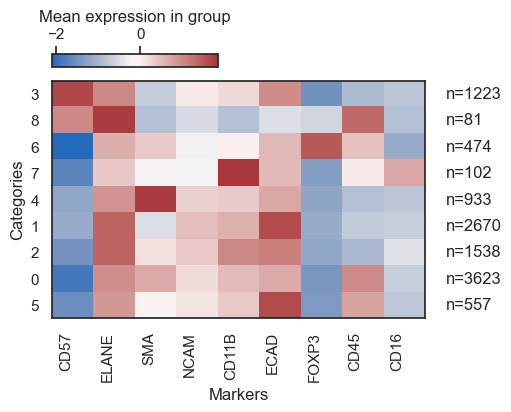

In [16]:
# construct a heatmap to examine the expression levels of specific markers across each identified cluster.
sm.pl.heatmap(adata, groupBy='leiden', standardScale='column', figsize=(5,4), showPrevalence=True)


In [17]:
# Based on the expression profile of markers, we shall assign a cell type to each cluster. Utilize the rename function for this purpose.
rename_dict = {'Tumor': ['5','1'],
               'Myeloid': ['2'],
               'Treg': ['6'],
               'Vessels': ['4'],
               'Artifacts': ['7'],
                'Immune': ['3','0']}

adata = sm.hl.rename(adata, rename=rename_dict, from_column='leiden', to_column='leiden_phenotype')

Renaming 5 to Tumor
Renaming 1 to Tumor
Renaming 2 to Myeloid
Renaming 6 to Treg
Renaming 4 to Vessels
Renaming 7 to Artifacts
Renaming 3 to Immune
Renaming 0 to Immune


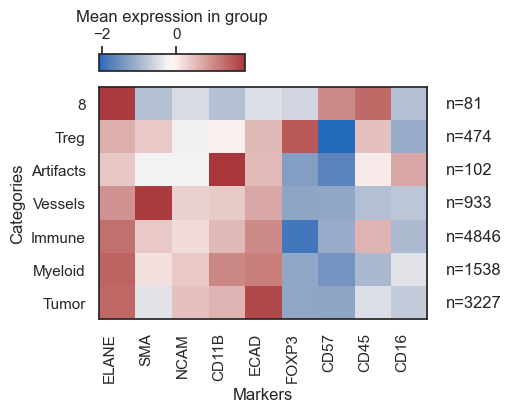

In [18]:
# now rebuild the heatmap to verify the expression pattern of markers within each cell type
sm.pl.heatmap(adata, groupBy='leiden_phenotype', standardScale='column', figsize=(5,4), showPrevalence=True)

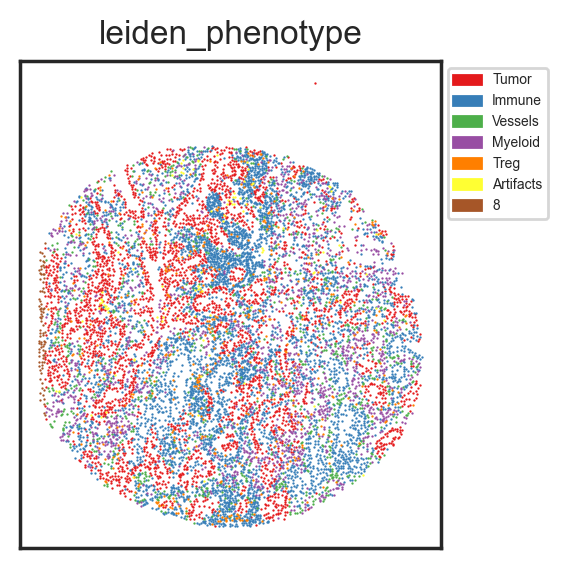

In [19]:
# Overlay the defined cell types on a spatial scatterplot too, just to see if they match up with the tissue's histology.
sm.pl.spatial_scatterPlot (adata, colorBy = ['leiden_phenotype'],figsize=(3,3), s=0.7, fontsize=5, catCmap='Set1')


In [ ]:
%pip install PyQt5

%gui qt


  Using cached PyQt5-5.15.11-cp38-abi3-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/6.9 MB ? eta -:--:--
   ------------ --------------------------- 2.1/6.9 MB 11.8 MB/s eta 0:00:01
   ---------------------- ----------------- 3.9/6.9 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------  6.8/6.9 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------- 6.9/6.9 MB 10.6 MB/s  0:00:00
   ---------------------------------------- 0.0/50.1 MB ? eta -:--:--
   - -------------------------------------- 2.1/50.1 MB 9.8 MB/s eta 0:00:05
   --- ------------------------------------ 3.9/50.1 MB 9.8 MB/s eta 0:00:05
   ----- ---------------------------------- 6.6/50.1 MB 10.3 MB/s eta 0:00:05
   ------ --------------------------------- 8.4/50.1 MB 10.2 MB/s eta 0:00:05
   -------- ------------------------------- 10.5/50.1 MB 10.2 MB/s eta 0:00:04
   ---------- ----------------------------- 12.8/50.1 MB 10.3 MB/s eta 0:00:04
   ------------ --

Gate confirmed for ELANE at 7.46
Gate confirmed for ELANE at 7.46
Gate confirmed for ELANE at 7.46
Gate confirmed for ELANE at 7.46
Gate confirmed for ELANE at 7.46
Gate confirmed for ELANE at 7.40
Gate confirmed for ELANE at 7.40


In [27]:
%pip install "napari[all]"
import scimap as sm
import napari
import sys

# 1. Import the specific module where the function lives
from scimap.plotting import image_viewer as iv_module

# 2. Inject 'napari' into that module's global namespace
# This makes 'napari' available to any function inside that file
iv_module.__globals__['napari'] = napari

# Your image path
image_path = r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\registration\exemplar-001.ome.tif'

# Now run the viewer
sm.pl.image_viewer(image_path=image_path, 
                   adata=adata, 
                   overlay='leiden_phenotype', 
                   point_size=10,
                   point_color='white')


# Note that if your AnnotatedData object (adata) includes multiple images, 
# you can use the `subset` parameter to specify the image name found in the `imageid` column, 
# enabling the loading of just that particular image.

Note: you may need to restart the kernel to use updated packages.


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\plotting\image_viewer.py:186: FutureWarning:

`napari.view_image` is deprecated and will be removed in napari 0.7.0.
Use `viewer = napari.Viewer(); viewer.add_image(...)` instead.



In [28]:
# Save the results
adata.write('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData.h5ad')

👽 Cell phenotyping using a Hierarchical Prior Knowledge Table

In [ ]:
# import packages
import scimap as sm
import anndata as ad
import pandas as pd

In [29]:
# Load the data that we saved in the last tutorial - (Prepare data for SCIMAP)
adata = ad.read_h5ad(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData.h5ad')

To run the method, you'll need two main components:
To successfully execute the method, you will need:

1) A .csv file containing manual gates. Should manual gates be absent, the algorithm will attempt to adjust the data by fitting two Gaussian distributions. Nonetheless, employing manual gating is recommended due to its heightened sensitivity.
2) A .csv file outlining a gating workflow strategy.
The execution of the algorithm is structured into three primary steps:

    1) Gate Identification: Utilize sm.pl.napariGater to identify the gates.
    2) Data Rescaling: Apply sm.pp.rescale to adjust the data based on the identified gates.
    3) Phenotyping: Process the rescaled data using sm.tl.phenotype to run the phenotyping algorithm.

Step 1: Define Manual Gates

In [ ]:
%gui qt

# This method will launch a napari window displaying several layers, each representing a different gate. You can toggle these layers on and off with the goal of identifying the gate that most accurately captures the positive cells. It's crucial to zoom and pan through the image to ensure the selected gate encompasses all positive cells throughout the image. Bear in mind that achieving 100% accuracy might not be feasible, so a certain margin of error may need to be accepted. This process is iterative, meaning adjustments may be necessary even after initial phenotyping and analysis. Manual gating must be conducted independently for each marker and each image.

In [ ]:
import scimap as sm
import napari
import magicgui
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
from matplotlib.figure import Figure
from PyQt5.QtWidgets import QLabel, QVBoxLayout, QWidget
from PyQt5.QtCore import Qt

# --- THE FIX STARTS HERE ---
# Import the function
from scimap.plotting.napariGater import napariGater

# inject napari & magicgui
napariGater.__globals__['napari'] = napari
napariGater.__globals__['magicgui'] = magicgui.magicgui

# inject matplotlib stuff
napariGater.__globals__['FigureCanvas'] = FigureCanvas
napariGater.__globals__['Figure'] = Figure

# inject PyQt5 stuff
napariGater.__globals__['QLabel'] = QLabel
napariGater.__globals__['QVBoxLayout'] = QVBoxLayout
napariGater.__globals__['QWidget'] = QWidget
napariGater.__globals__['Qt'] = Qt
# --- THE FIX ENDS HERE ---

# Your code
image_path = r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\registration\exemplar-001.ome.tif'
sm.pl.napariGater(image_path, adata)


C:\Users\chuab\AppData\Local\Temp\ipykernel_8344\2688676849.py:30: UserWarning:

NOTE: napariGater() is currently in beta testing. If you encounter any issues, please report them at: https://github.com/labsyspharm/scimap/issues



Initializing...
Loading image data...
Calculating contrast settings...
Initialization completed in 0.01 seconds
Opening napari viewer...
Napari viewer initialized in 22.16 seconds


In [42]:
# check the gates
adata.uns['gates']

,exemplar-001--unmicst_cell
ELANE,7.400000
CD57,7.207101
CD45,7.026793
CD11B,7.093026
SMA,6.598185
CD16,6.294400
ECAD,7.380445
FOXP3,7.319345
NCAM,6.868325


Multiple Images and Uniform Gates 🛠️
If you have multiple images and want to apply the same gate to all of them, you have two options:

1) Copy-paste the same gate values across all columns in your CSV file. 🖋️
2)  Alternatively, use just one column named "gates" (with no additional columns). In this case, the same gate will be applied to all images in your dataset, provided there is more than one image. ✅

A Final Note 📝

When you run the rescale function without specifying anything for the gate parameter, it will try to auto-identify gates using a GMM (Gaussian Mixture Model) function. ⚠️ However, this method is generally not very accurate, and we discourage relying on it. 🚫

If gates are missing for some images or markers, the GMM will be automatically applied. 🔄 Be cautious when interpreting results for those images or markers! 🧐

In [45]:
import pandas as pd
# Do the above step for each marker and then create a `.csv` file like below:
pd.read_csv(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\manual_gates.csv')

,marker,exemplar-001--unmicst_cell
0,ELANE,7.80
1,CD57,8.90
2,CD45,6.40
3,CD11B,7.60
4,SMA,7.50
5,CD16,6.50
6,ECAD,7.35
7,FOXP3,7.40
8,NCAM,7.00


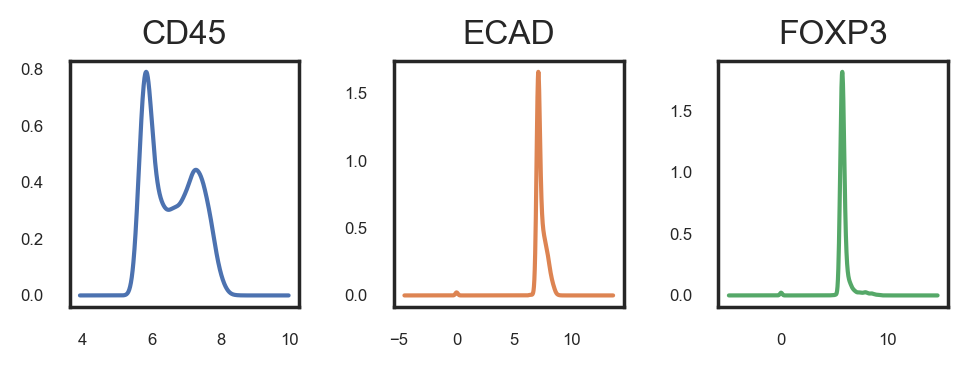

In [ ]:
#Although visual gating has proven to be the most sensitive method for us, you can also apply single and bi-marker gating approaches, similar to FACS, to assist in determining a threshold.
# single 
sm.pl.distPlot(adata, layer='log', markers=['CD45','ECAD','FOXP3'], ncols=3, fontsize=6, figsize=(5,2))

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\mpl_scatter_density\generic_density_artist.py:77: RuntimeWarning:

All-NaN slice encountered

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\mpl_scatter_density\generic_density_artist.py:82: RuntimeWarning:

All-NaN slice encountered



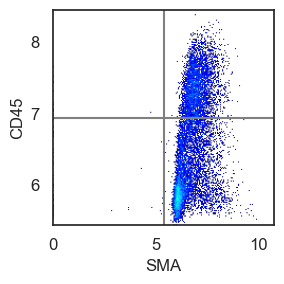

In [47]:
#We also use bimarker gating to identify a gate
sm.pl.densityPlot2D(adata, markerA='SMA', markerB='CD45', layer='log')

Step 2: Resclae the data

In [ ]:
import pandas as pd
import scimap as sm

# 1. Load the file
manual_gate = pd.read_csv(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\manual_gates.csv')

# 2. RENAME column to 'markers' (plural) if it's currently singular
# This aligns it with what scimap expects internally
manual_gate = manual_gate.rename(columns={'marker': 'markers'})

# 3. FORCE it to be string type (to fix the int64 vs object error)
manual_gate['markers'] = manual_gate['markers'].astype(str)

# 4. Ensure AnnData uses string index too
adata.var.index = adata.var.index.astype(str)

# 5. Run rescale
adata = sm.pp.rescale(adata, gate=manual_gate)

# As you can see GMM was automatically applied to SMA and FOXP3



Scaling Image: exemplar-001--unmicst_cell
Scaling ELANE (gate: 7.800)
Scaling CD57 (gate: 8.900)
Scaling CD45 (gate: 6.400)
Scaling CD11B (gate: 7.600)
Scaling SMA (gate: 7.500)
Scaling CD16 (gate: 6.500)
Scaling ECAD (gate: 7.350)
Scaling FOXP3 (gate: 7.400)
Scaling NCAM (gate: 7.000)


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\preprocessing\rescale.py:145: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



Step 3: Run the phenotyping algorithm

In [52]:
# load the phenotyping workflow
phenotype = pd.read_csv(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\phenotype_workflow.csv')
# view the table:
phenotype.style.format(na_rep='')

,Unnamed: 0,Unnamed: 1,ELANE,CD57,CD45,CD11B,SMA,CD16,ECAD,FOXP3,NCAM
0,all,ECAD+,,,,,,,pos,,
1,all,Immune,,,pos,,,,,,
2,all,SMA+,,,,,pos,,,,
3,Immune,NK cells,,allpos,,neg,,allpos,,,
4,Immune,Other myeloid cells,,,,pos,,,,,
5,Immune,Treg,,,,,,,,pos,
6,Other myeloid cells,Dendritic cells,,allneg,,,,allneg,,,


As it can be seen from the table above:

The first column has to contain the cell that are to be classified.

The second column indicates the phenotype a particular cell will be assigned if it satifies the conditions in the row.

Column three and onward represent protein markers. If the protein marker is known to be expressed for that cell type, then it is denoted by either pos, allpos. If the protein marker is known to not express for a cell type it can be denoted by neg, allneg. If the protein marker is irrelevant or uncertain to express for a cell type, then it is left empty. anypos and anyneg are options for using a set of markers and if any of the marker is positive or negative, the cell type is denoted accordingly.

To give users maximum flexibility in identifying desired cell types, we have implemented various classification arguments as described above for strategical classification. They include
1) allpos
2) allneg
3) anypos
4) anyneg
5) pos
6) neg

pos : "Pos" looks for cells positive for a given marker. If multiple markers are annotated as pos, all must be positive to denote the cell type. For example, a Regulatory T cell can be defined as CD3+CD4+FOXP3+ by passing pos to each marker. If one or more markers don't meet the criteria (e.g. CD4-), the program will classify it as Likely-Regulatory-T cell, pending user confirmation. This is useful in cases of technical artifacts or when cell types (such as cancer cells) are defined by marker loss (e.g. T-cell Lymphomas).

neg : Same as pos but looks for negativity of the defined markers.

allpos : "Allpos" requires all defined markers to be positive. Unlike pos, it doesn't classify cells as Likely-cellType, but strictly annotates cells positive for all defined markers.

allneg : Same as allpos but looks for negativity of the defined markers.

anypos : "Anypos" requires only one of the defined markers to be positive. For example, to define macrophages, a cell could be designated as such if any of CD68, CD163, or CD206 is positive.

anyneg : Same as anyneg but looks for negativity of the defined markers.

In [53]:
adata = sm.tl.phenotype_cells (adata, phenotype=phenotype, label="phenotype") 


Phenotyping ECAD+
Phenotyping Immune
Phenotyping SMA+
-- Subsetting Immune
Phenotyping NK cells
Phenotyping Other myeloid cells
Phenotyping Treg
-- Subsetting Other myeloid cells
Phenotyping Dendritic cells
Consolidating the phenotypes across all groups


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\tools\phenotype_cells.py:174: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\tools\phenotype_cells.py:290: FutureWarning:

DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\tools\phenotype_cells.py:290: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



In [54]:
# Summary of the phenotyping
adata.obs['phenotype'].value_counts()

phenotype
Immune                 4746
ECAD+                  3015
Unknown                2278
SMA+                    602
Treg                    282
Other myeloid cells     193
NK cells                 66
Dendritic cells          19
Name: count, dtype: int64

Visualisation of the Results

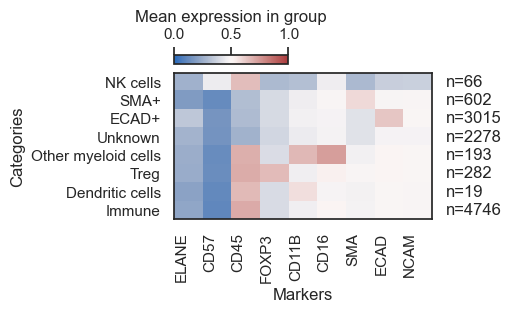

In [55]:
# Heatmap (here values over 0.5 are considered positive as we have scaled the data)
sm.pl.heatmap(adata, groupBy='phenotype', standardScale=None, figsize=(5,3), showPrevalence=True, vmin=0, vmax=1)


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\plotting\umap.py:304: UserWarning:

No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored



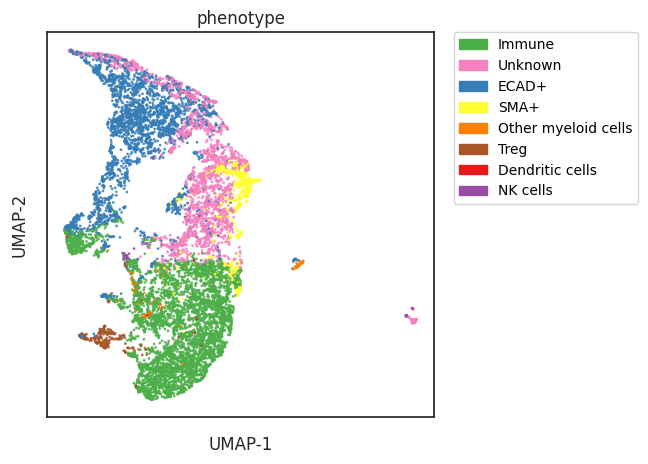

In [56]:
# view the phenotype on a UMAP
adata = sm.tl.umap(adata)
sm.pl.umap(adata, color=['phenotype'], s=1)

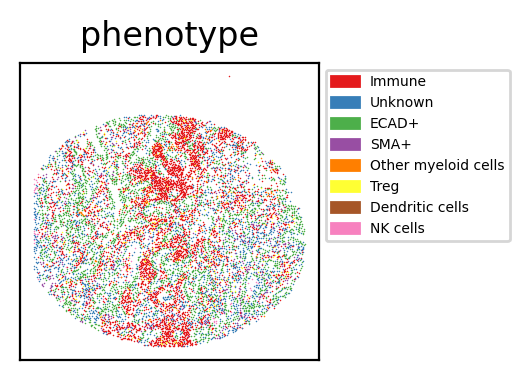

In [57]:
# spatial scatter plot to look at the distribution of cells
sm.pl.spatial_scatterPlot (adata, colorBy = ['phenotype'],figsize=(2.75,2), s=0.3, fontsize=5, catCmap='Set1')

In [58]:
# View the results by overlaying it on the raw image
image_path = r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\registration/exemplar-001.ome.tif'

# view in napari
sm.pl.image_viewer(image_path=image_path, 
                   adata=adata, 
                   overlay='phenotype', 
                   point_size=10,
                   point_color='white')

# Note that if your AnnotatedData object (adata) includes multiple images, 
# you can use the `subset` parameter to specify the image name found in the `imageid` column, 
# enabling the loading of just that particular image.

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\plotting\image_viewer.py:186: FutureWarning:

`napari.view_image` is deprecated and will be removed in napari 0.7.0.
Use `viewer = napari.Viewer(); viewer.add_image(...)` instead.



In [59]:
# Save the results
adata.write(r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData.h5ad')

🙌 Add Region of Interest (ROIs) for Comparitive Analysis
Frequently, adding Regions of Interest (ROIs) to an image is crucial for conducting comparative analysis, such as identifying distinct histological sites, tumor regions, or boundaries. To incorporate ROIs into scimap, there are two approaches:

1) Directly drawing on the image using napari.
2) For images stored on OMERO, ROIs can be added, exported, and then imported into scimap.

In [74]:
# import packages
import scimap as sm
import anndata as ad
%gui qt
image_path = r'C:\Users\chuab\Desktop\SciMap_project\scimapExampleData\scimapExampleData\registration/exemplar-001.ome.tif'

In [103]:
import scimap as sm
import napari

# --- THE FIX STARTS HERE ---
# Import the specific function
from scimap.plotting.addROI_image import addROI_image

# Inject 'napari' into this function's global scope
addROI_image.__globals__['napari'] = napari
# --- THE FIX ENDS HERE ---

# Now run the function
adata = sm.pl.addROI_image(image_path, adata)


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\plotting\addROI_image.py:239: FutureWarning:

`napari.view_image` is deprecated and will be removed in napari 0.7.0.
Use `viewer = napari.Viewer(); viewer.add_image(...)` instead.




        Opening Napari;
        Add shape layers (on left) to draw ROI's. 
        Rename the shape layer to give a name to your ROI
        Multiple shape layers are supported
        ROI's should not overlap
        Close Napari to save ROI's.
        
Identifying cells within selected ROI's
ROIs saved under adata.obs['ROI']


In [105]:
# print the number of cells within the assigned ROIs
adata.obs['ROI'].value_counts()

ROI
Other        10519
ROI_CD45       507
ROI_CD57        98
ROI_ECAD        57
ROI_CD118       20
Name: count, dtype: int64

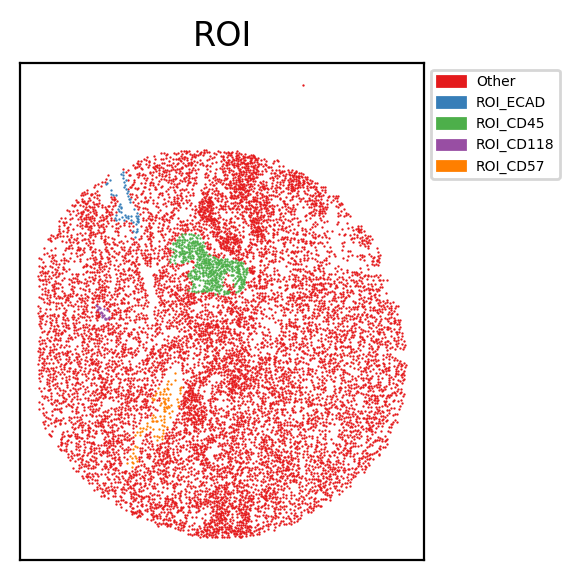

In [106]:
# check the added ROIs
sm.pl.spatial_scatterPlot (adata, colorBy = ['ROI'],figsize=(3,3), s=0.7, fontsize=5, catCmap='Set1')

In [107]:
print(adata.obs.columns)


Index(['X_centroid', 'Y_centroid', 'Area', 'MajorAxisLength',
       'MinorAxisLength', 'Eccentricity', 'Solidity', 'Extent', 'Orientation',
       'CellID', 'imageid', 'leiden', 'leiden_phenotype', 'ROI'],
      dtype='object')


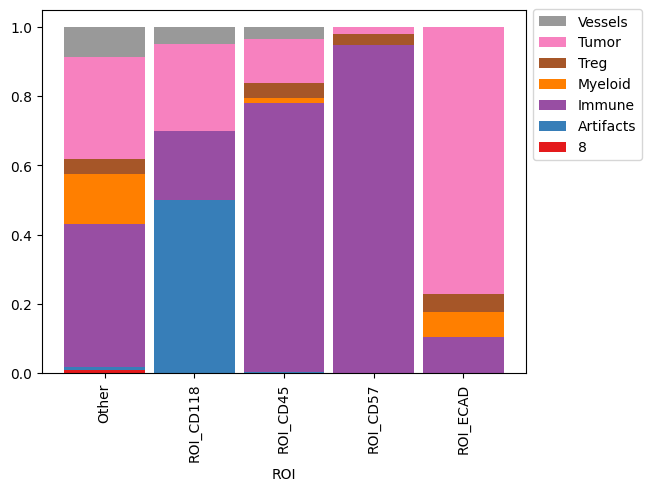

In [108]:
# We can now do any downstream analysis for example let's look at the distribution of cell types within these ROIs
# Use the correct column name found in your adata.obs
sm.pl.stacked_barplot(adata, x_axis='ROI', y_axis='leiden_phenotype')


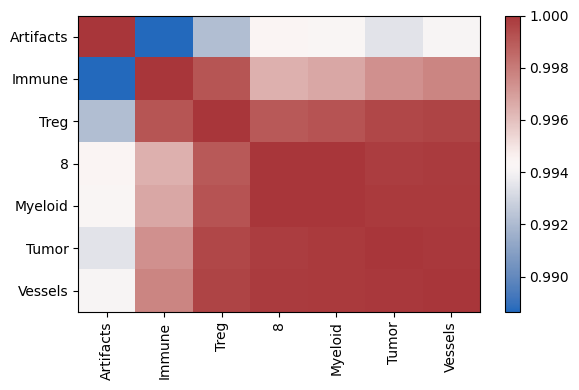

In [109]:
# or look at the correaltion of cell types between ROIs
sm.pl.groupCorrelation(adata, groupBy='leiden_phenotype', condition='ROI', figsize=(6,4))

In [110]:
# Save the results
adata.write('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')

🤩 Cell-Type Proportion Exploration


In [111]:
# import packages
import scimap as sm
import anndata as ad
# Load the data that we saved in the last tutorial (with ROIs added)
adata = ad.read_h5ad('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')

Investigate cell-type composition within the ROI's


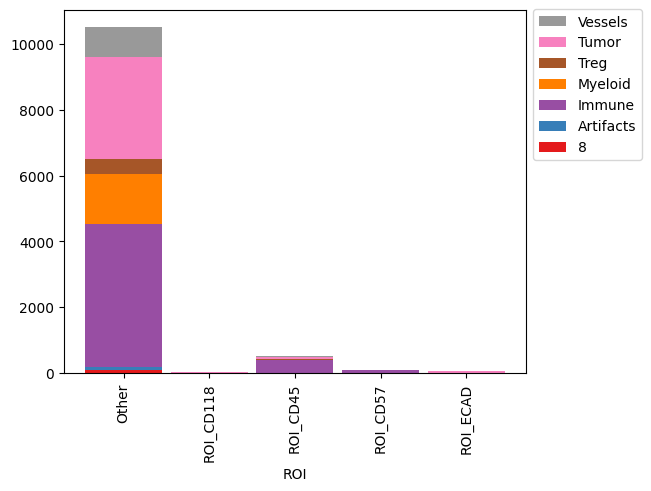

In [112]:
# plots the absolute count of cells within each ROI
sm.pl.stacked_barplot (adata,
                       x_axis='ROI',
                       y_axis='leiden_phenotype',
                       method='absolute')

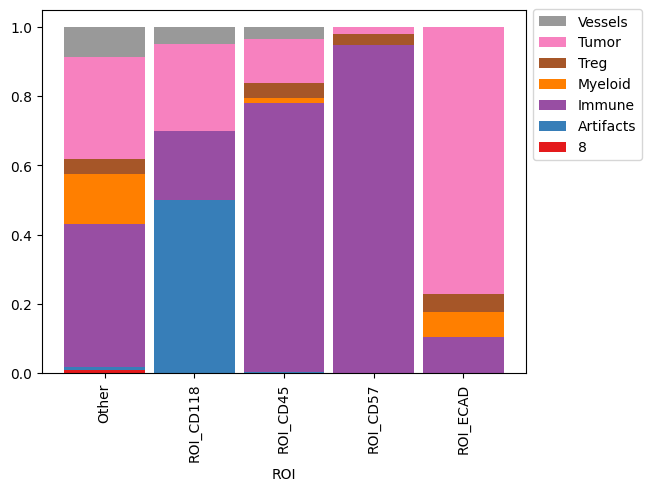

In [113]:
# Plot the number of cells normalized to 100% 
sm.pl.stacked_barplot (adata,
                       x_axis='ROI',
                       y_axis='leiden_phenotype',
                       method='percent')

Compute the fold change in cell types across various ROIs.

In [114]:
print(adata.obs['ROI'].unique())


['Other', 'ROI_ECAD', 'ROI_CD45', 'ROI_CD118', 'ROI_CD57']
Categories (5, object): ['Other', 'ROI_CD45', 'ROI_CD57', 'ROI_CD118', 'ROI_ECAD']


In [ ]:
adata = sm.tl.foldchange(adata, 
                         from_group=['ELANE_ROI'],  # Use your actual ROI name here
                         to_group=['CD45_ROI'],     # Optional: compare to the other ROI
                         imageid='ROI', 
                         phenotype='leiden_phenotype',
                         normalize=True, 
                         label='foldchange')


calculating foldchange
calculating P values


c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\seaborn\matrix.py:530: ClusterWarning:

The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix



ValueError: The number of observations cannot be determined on an empty distance matrix.

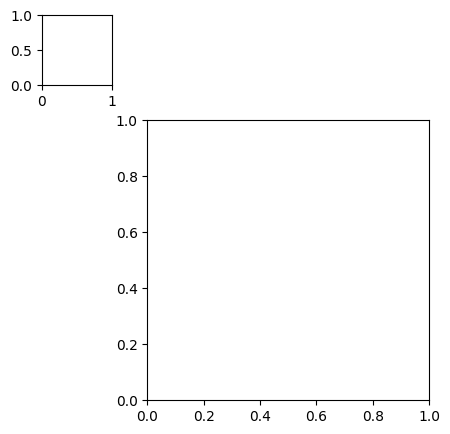

In [119]:
# Now let's plot the results
# Force p_val to 1.0 to show raw fold changes without statistical filtering
sm.pl.foldchange(adata, 
                 label='foldchange', 
                 method='heatmap', 
                 p_val=1.0,           # <--- THIS IS CRITICAL
                 nonsig_color='grey', 
                 figsize=(5,5),
                 log=True, 
                 center=0, 
                 linecolor='black',
                 linewidths=1,
                 col_cluster=False)   # Prevents clustering error on single column


IndexError: list index out of range

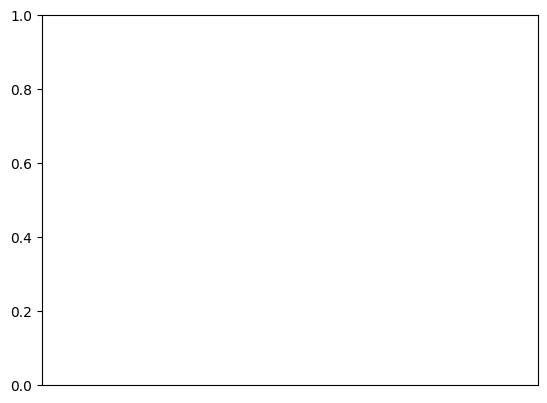

In [120]:
# lets plot the same results differently (this would be more useful when you have more groups to compare)

# Parallel_coordinates plot of the foldchanges
sm.pl.foldchange (adata, label='foldchange', 
                log=True, method='parallel_coordinates', 
                invert_axis=True,
                xticks_rotation=90,
                return_data = False)

Exploring the phenotypes overlaid on a UMAP

In [121]:
# view the phenotype on a UMAP
adata = sm.tl.umap(adata)

c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



c:\Users\chuab\anaconda3\envs\scimap\lib\site-packages\scimap\plotting\umap.py:342: UserWarning:

No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored



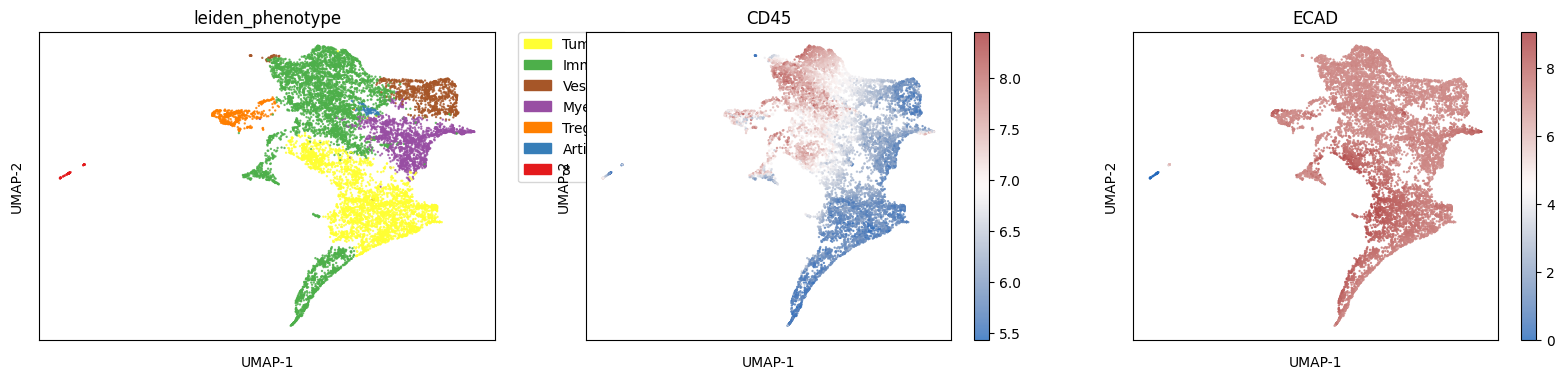

In [123]:
# Use 'leiden_phenotype' instead of 'phenotype'
sm.pl.umap(adata, color=['ECAD', 'CD45', 'leiden_phenotype'], s=0.5, figsize=(20, 4))


Exploring the expression of markers with phenotypes

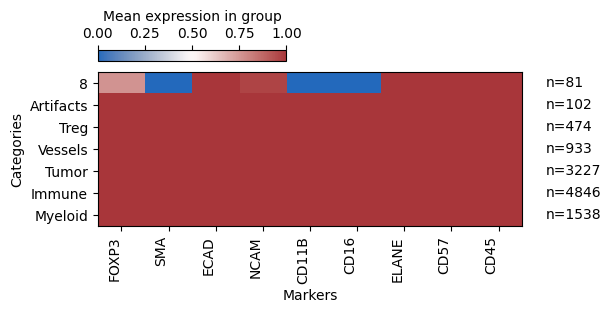

In [125]:
# Heatmap (here values over 0.5 are considered positive as we have scaled the data)
sm.pl.heatmap(adata, groupBy='leiden_phenotype', standardScale=None, figsize=(6,3), showPrevalence=True, vmin=0, vmax=1)

Exploring the correlation of markers


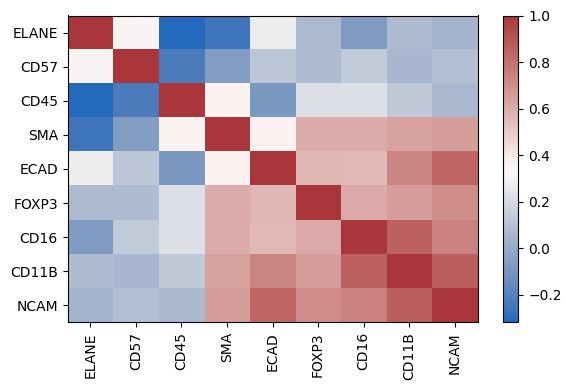

In [126]:
sm.pl.markerCorrelation(adata, figsize=(6,4))

Exploring the correlation of abundance of cell types between conditions


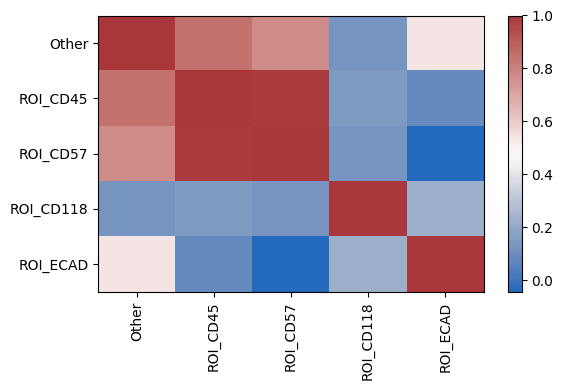

In [127]:
sm.pl.groupCorrelation(adata, groupBy='ROI', condition='leiden_phenotype', figsize=(6,4))

In [128]:
# Save the results
adata.write('C:\\Users\\chuab\\Desktop\\SciMap_project\\scimapExampleData\\scimapExampleData.h5ad')